# The powerplay risk ledger

**The question, given the earlier findings.** The league-level accounting said the 2024 powerplay approach was worth about four win-probability points per powerplay, that the expected wicket cost given the situations faced did not change, and that the realised cost was mostly luck. A coach does not manage a league; a coach manages an innings and a season. This notebook puts the same accounting at those two levels: for every powerplay, what was taken on, what it was expected to cost, what it cost, and what it bought; then per team and season with intervals.

**What this notebook does.**
1. *Per ball.* The situation-only expected-wicket model (the logistic model that carried the expected-wickets analysis) is refitted out-of-fold so the ledger is self-contained, and every powerplay delivery carries its expected-wicket value, its outcome category, the price of that outcome (mean change in win probability on such balls, both seasons pooled) and the actual change.
2. *Per innings.* One row per powerplay: balls, aggressive-shot share, sixes, fours, wickets, expected wickets (the sum of per-ball values), the wicket residual (actual minus expected, the luck component), the value of the outcome mix at fixed prices, and that value with the expected wicket cost in place of the realised one.
3. *Per team-season.* Means per powerplay with a match bootstrap interval, and the figure.

**How to read this notebook.** Points are percentage points of win probability per powerplay, priced at pooled prices (a six +4.6, a four +2.8, a dot −1.0, a wicket −4.5). `expected_wickets` is what the situations faced would have cost an average side; it barely varies between innings (about 1.4 to 1.5) because the model is situation-only, so the wicket residual is nearly all the wickets a side lost above or below that constant. A team-season is fourteen powerplays, so team rows are read as tiers. The win-probability model is team-agnostic and weaker in first innings; prices are averages over game states.

**Numbers in the text.** Quoted from the run of 13 September 2026 under the seed in `config.toml`; if a table disagrees with a paragraph, the table is current. Code lives in `scripts/powerplay_risk_ledger/`.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("scripts").resolve()))

from common.config import load_settings
from common import results_io
from mean_level_and_tail import season_contrast_bootstrap as scb
from powerplay_risk_ledger import ledger as pl

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

settings = load_settings()
ANALYSIS = "powerplay_risk_ledger"
SEED = settings.seed("expected_wickets")
N_ITER = settings.n_resamples
PRODUCER = "powerplay_risk_ledger.ipynb"
YEARS = (settings.earlier_season, settings.later_season)
print(f"root={settings.root}  seed={SEED}  resamples={N_ITER}")

root=/Users/madkad/dpl_2026_s1  seed=202609081209  resamples=10000


## Data

In [2]:
DATA_PATH = settings.data_path("cleaned_dataset")
USING_FIXTURE = not DATA_PATH.exists()
if USING_FIXTURE:
    from common.synthetic_ballframe import make_synthetic_ballframe
    df = make_synthetic_ballframe(seed=7)
    print("REAL DATA ABSENT: running on the synthetic fixture (its wprob is noise; mechanics only)")
else:
    df = scb.load_cleaned_dataset(str(DATA_PATH))
print(f"rows={len(df):,}  matches={df['p_match'].nunique()}")
EXTRA = {"n_resamples": N_ITER, "fixture": USING_FIXTURE, "xw_model": "logistic, situation variant, out-of-fold", "prices": "pooled over both seasons"}

rows=34,967  matches=145


## Per ball

Every powerplay delivery with its expected-wicket value, outcome category, price and actual win-probability change; the pooled prices alongside. Found: 10,534 deliveries, 10,133 of them legal and carrying an expected-wicket value.

In [3]:
balls, prices = pl.per_ball_ledger(df, settings, SEED)
balls.to_parquet(settings.output_dir(ANALYSIS) / "per_ball_ledger.parquet", index=False)
results_io.write_table(prices, settings, ANALYSIS, "outcome_prices_pooled", SEED, PRODUCER, EXTRA)
print(f"powerplay deliveries: {len(balls):,}  with expected wickets: {int(balls['xw'].notna().sum()):,}")
display(prices.round(3))
balls.head()

powerplay deliveries: 10,534  with expected wickets: 10,133


,outcome_category,price_points,balls
0,six,4.561,565
1,four,2.807,1859
2,one_to_three,0.117,3209
3,no_run,-1.039,3879
4,wicket,-4.511,434
5,wide,1.138,348
6,no_ball,2.768,52
7,bye_or_leg_bye,0.314,188


,p_match,year,inns,team_bat,team_bowl,over_num,ball,outcome_category,price_points,delta_wprob,xw,legal,faced,aggressive,six,four,wicket,batruns,score
0,1359475,2023,1,Chennai Super Kings,Gujarat Titans,1,2,bye_or_leg_bye,0.314255,-1.15,0.042322,1,1,0,0,0,0,0,1
1,1359475,2023,1,Chennai Super Kings,Gujarat Titans,1,3,no_run,-1.038742,-1.15,0.041776,1,1,0,0,0,0,0,0
2,1359475,2023,1,Chennai Super Kings,Gujarat Titans,1,4,one_to_three,0.117392,0.00,0.041736,1,1,0,0,0,0,1,1
3,1359475,2023,1,Chennai Super Kings,Gujarat Titans,1,5,no_run,-1.038742,-2.30,0.042199,1,1,0,0,0,0,0,0
4,1359475,2023,1,Chennai Super Kings,Gujarat Titans,1,6,no_run,-1.038742,-1.14,0.042159,1,1,0,0,0,0,0,0


## Per innings

One row per powerplay, written as `per_innings_ledger.csv`; the season means, then the ten most valuable powerplays.

In [4]:
innings = pl.per_innings_ledger(balls, prices)
results_io.write_table(innings, settings, ANALYSIS, "per_innings_ledger", SEED, PRODUCER, EXTRA)
display(innings.groupby("year")[["attempt_share", "sixes", "wickets", "expected_wickets", "wicket_residual",
                                 "expected_wicket_cost_points", "realised_wicket_cost_points", "boundary_value_points",
                                 "value_points", "expected_net_points"]].mean().round(3))
innings.sort_values("value_points", ascending=False).head(10).round(2)

,attempt_share,sixes,wickets,expected_wickets,wicket_residual,expected_wicket_cost_points,realised_wicket_cost_points,boundary_value_points,value_points,expected_net_points
year,,,,,,,,,,
2023,0.158,1.660,1.429,1.479,-0.050,-6.672,-6.445,25.518,7.861,7.634
2024,0.160,2.317,1.577,1.484,0.093,-6.697,-7.117,28.870,11.461,11.881


,year,p_match,inns,team_bat,team_bowl,deliveries,legal_balls,faced,aggressive_shots,sixes,fours,wickets,runs,expected_wickets,value_points,actual_wprob_change,attempt_share,expected_wicket_cost_points,realised_wicket_cost_points,wicket_residual,luck_points,boundary_value_points,value_excluding_wickets_points,expected_net_points
215,2024,1426273,1,Sunrisers Hyderabad,Delhi Capitals,35,35,35,15,11,13,0,125,1.45,83.52,43.61,0.43,-6.55,-0.00,-1.45,6.55,86.65,83.52,76.97
260,2024,1426295,2,Sunrisers Hyderabad,Lucknow Super Giants,37,35,35,13,8,13,0,107,1.53,66.68,36.01,0.37,-6.89,-0.00,-1.53,6.89,72.97,66.68,59.79
250,2024,1426290,2,Royal Challengers Bengaluru,Gujarat Titans,35,35,35,8,7,10,1,92,1.47,48.23,21.16,0.23,-6.63,-4.51,-0.47,2.12,59.99,52.74,46.11
230,2024,1426280,2,Punjab Kings,Kolkata Knight Riders,36,35,35,6,7,9,1,92,1.47,48.03,10.67,0.17,-6.64,-4.51,-0.47,2.13,57.18,52.54,45.90
231,2024,1426281,1,Delhi Capitals,Mumbai Indians,38,35,36,5,5,11,0,88,1.43,44.95,35.56,0.14,-6.43,-0.00,-1.43,6.43,53.68,44.95,38.52
161,2024,1422126,1,Sunrisers Hyderabad,Mumbai Indians,37,36,37,11,4,10,1,80,1.51,39.14,41.09,0.30,-6.79,-4.51,-0.51,2.28,46.31,43.65,36.85
206,2024,1426268,2,Royal Challengers Bengaluru,Sunrisers Hyderabad,35,35,35,16,4,11,0,78,1.47,38.75,1.19,0.46,-6.64,-0.00,-1.47,6.64,49.12,38.75,32.11
177,2024,1422134,1,Kolkata Knight Riders,Delhi Capitals,37,35,35,12,4,12,1,84,1.47,38.12,43.76,0.34,-6.64,-4.51,-0.47,2.13,51.92,42.64,36.00
229,2024,1426280,1,Kolkata Knight Riders,Punjab Kings,38,35,35,11,4,9,0,76,1.42,37.94,34.88,0.31,-6.42,-0.00,-1.42,6.42,43.50,37.94,31.52
6,2023,1359478,1,Rajasthan Royals,Sunrisers Hyderabad,36,35,35,10,3,13,1,85,1.48,37.35,51.81,0.29,-6.68,-4.51,-0.48,2.17,50.17,41.86,35.18


At the season level the ledger reproduces the league accounting from the innings up: the value of the powerplay mix was 7.9 points per powerplay in 2023 and 11.5 in 2024, a gain of 3.6 (the league ledger's 3.8 at 2023 prices), of which the boundary value rose 3.4 (25.5 to 28.9) and the wicket cost 0.7 (6.4 to 7.1). Expected wickets were 1.48 per powerplay in both seasons; the residual moved from −0.05 to +0.09 wickets, the luck component. Attempt share was unchanged at 16%.

The ten most valuable powerplays are all but one from 2024 and four of them belong to Sunrisers, whose best (125 for 0 with eleven sixes at an attempt share of 43%) was worth 84 points against an expected wicket cost of 6.5 that was never paid. The list is a reminder of what the ledger prices: a powerplay can take on a great deal of risk and lose nothing, and the expected-cost column is what says how much was being risked.

## Per team-season

Means per powerplay with match bootstrap intervals; then the figure.

In [5]:
team = pl.per_team_season_ledger(innings, settings, SEED, N_ITER)
results_io.write_table(team, settings, ANALYSIS, "per_team_season_ledger", SEED, PRODUCER, EXTRA)
show = ["team", "season", "powerplays", "attempt_share", "sixes", "wickets", "expected_wickets", "wicket_residual",
        "expected_wicket_cost_points", "realised_wicket_cost_points", "boundary_value_points", "value_points", "value_points_low", "value_points_high"]
team[show].round(3)

,team,season,powerplays,attempt_share,sixes,wickets,expected_wickets,wicket_residual,expected_wicket_cost_points,realised_wicket_cost_points,boundary_value_points,value_points,value_points_low,value_points_high
0,Chennai Super Kings,2023,15,0.144,1.933,0.600,1.489,-0.889,-6.719,-2.707,25.845,14.234,9.927,18.723
1,Royal Challengers Bengaluru,2023,14,0.126,1.929,0.786,1.496,-0.710,-6.750,-3.545,26.638,13.353,9.236,17.402
2,Mumbai Indians,2023,16,0.192,2.500,1.375,1.477,-0.102,-6.662,-6.203,28.417,11.115,3.465,17.970
3,Rajasthan Royals,2023,14,0.136,1.857,1.286,1.480,-0.194,-6.678,-5.800,29.520,10.879,1.950,19.152
4,Gujarat Titans,2023,17,0.166,0.941,1.235,1.483,-0.247,-6.689,-5.573,24.435,8.873,2.727,15.127
5,Punjab Kings,2023,14,0.159,1.714,1.929,1.473,0.455,-6.647,-8.701,26.664,6.448,2.089,10.984
6,Delhi Capitals,2023,14,0.188,1.286,1.929,1.483,0.445,-6.692,-8.701,24.508,3.548,-5.207,12.006
7,Kolkata Knight Riders,2023,14,0.173,2.071,2.071,1.469,0.603,-6.626,-9.345,25.486,3.432,-2.427,9.709
8,Lucknow Super Giants,2023,15,0.163,1.533,1.467,1.477,-0.010,-6.662,-6.617,22.149,3.308,-4.887,12.247
9,Sunrisers Hyderabad,2023,14,0.131,0.857,1.714,1.461,0.253,-6.592,-7.734,21.552,2.608,-2.536,7.768


In 2024 the ledger separates the league into three tiers. Sunrisers (20.5 points per powerplay, attempt share 19%, 3.7 sixes), Kolkata (20.0, 24%, 3.1) and Delhi (16.2, 22%, 3.3) took the most risk and were paid for it; Bengaluru (13.8) and Mumbai (9.8) sat in the middle; Chennai, Rajasthan, Punjab, Lucknow and Gujarat (3.4 to 8.7) attacked less (attempt share 12% to 13%) and bought less. The 2023 ordering was almost the reverse at the top: Chennai and Bengaluru led on 14 and 13 points, largely by losing few wickets (0.6 and 0.8 per powerplay against an expected 1.5), and Sunrisers were last on 2.6.

On the wicket side, no team-season paid much more or less than the situations predicted: realised costs run from 2.7 to 9.3 points against an expected 6.6 to 6.8, and the largest residuals (Chennai and Bengaluru in 2023 on the lucky side, Kolkata 2023 and Delhi 2024 on the unlucky) are half a wicket per powerplay. The gap between teams is in what they bought, not in what they paid: the boundary value ranges from 22 to 36 points per powerplay, the realised wicket cost across a band a third as wide.

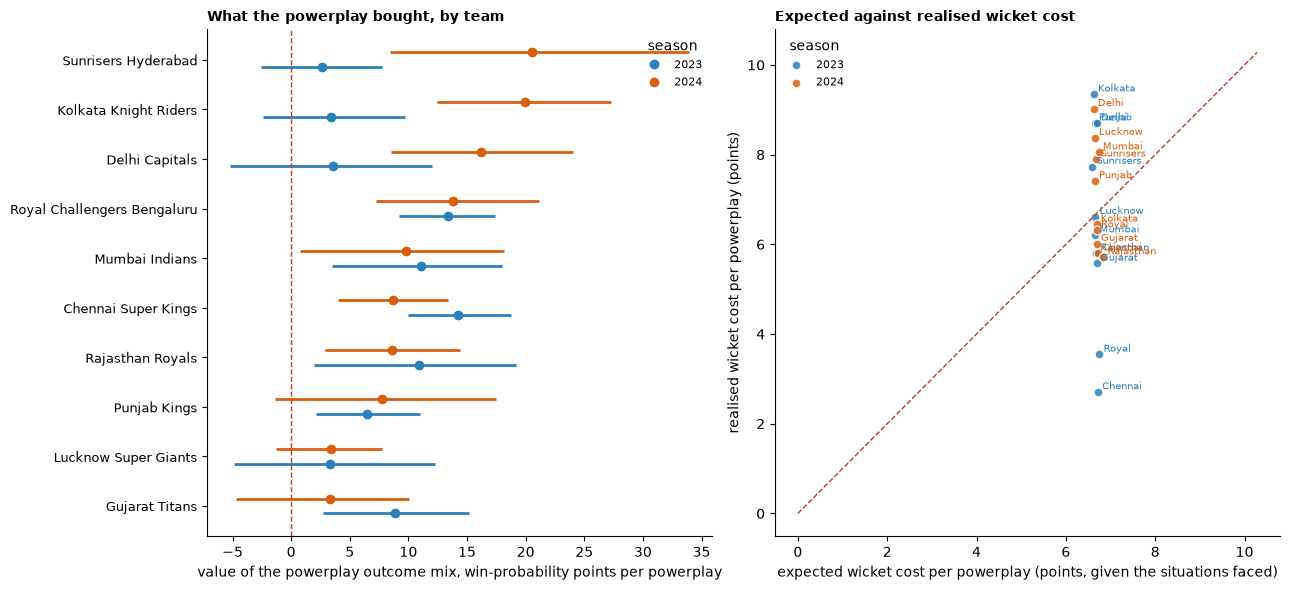

In [6]:
fig = pl.plot_team_ledger(team, YEARS[0], YEARS[1])
results_io.write_figure(fig, settings, ANALYSIS, "team_season_ledger", SEED, PRODUCER)
plt.show()

At the innings and team level the powerplay ledger says the same thing the league ledger said, with names attached: in 2024 the sides that attacked the powerplay hardest (Sunrisers, Kolkata, Delhi) bought two to three times the win-probability value of the sides that did not, and paid a wicket cost no different from what their situations predicted. Risk in the 2024 powerplay was cheap to carry and expensive to forgo. The intervals on fourteen powerplays are wide, so these are tiers, and the aggressive tier is the same three teams the dispersion work placed in the aggressive wing.